# Concentração de mercado

Este notebook responde às seguintes perguntas do projeto:

1. Quão concentrada é a produção de cerveja no Brasil?
2. A concentração mudou de 2024 para 2025?
3. Como a concentração varia entre regiões?

## Preparação

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src.metricas import pontos_lorenz, gini_trapezios, variacao_pct

pd.options.display.float_format = "{:,.4f}".format

PASTA_SAIDA = Path("../data/processed")
PASTA_FIGURAS = Path("../docs/figuras")
PASTA_FIGURAS.mkdir(exist_ok=True)

In [2]:
COR_SERIE = "#2a78d6"
COR_TEXTO = "#0b0b0b"
COR_TEXTO_2 = "#52514e"
COR_GRADE = "#e4e3df"
COR_FUNDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": COR_FUNDO,
    "axes.facecolor": COR_FUNDO,
    "axes.edgecolor": COR_GRADE,
    "axes.labelcolor": COR_TEXTO_2,
    "xtick.color": COR_TEXTO_2,
    "ytick.color": COR_TEXTO_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": COR_GRADE,
    "grid.linewidth": 0.8,
    "font.size": 10,
})

## 1. Quão concentrada é a produção?

A Tabela 19 informa a fatia do volume produzida pelas maiores cervejarias em seis pontos (1%, 2%, 3%, 4%, 5% e 10%). Convertemos esses pontos em uma curva de Lorenz e calculamos o índice de Gini pela regra dos trapézios.

Com apenas seis pontos, o Gini calculado é um **limite inferior**: a curva real fica abaixo dos segmentos retos que ligam os pontos, então a concentração real é igual ou maior.

In [3]:
conc_2025 = pd.read_csv(PASTA_SAIDA / "tabela_19_concentracao_2025.csv")

lorenz_2025 = pontos_lorenz(conc_2025["pct_cervejarias"], conc_2025["pct_volume"])
gini_2025 = gini_trapezios(lorenz_2025["pop_acumulada"], lorenz_2025["volume_acumulado"])

print(f"Gini 2025 (limite inferior): {gini_2025:.4f}")
lorenz_2025

Gini 2025 (limite inferior): 0.9644


,pop_acumulada,volume_acumulado
0,0.0000,0.0000
1,0.9000,0.0050
2,0.9500,0.0138
3,0.9600,0.0343
4,0.9700,0.1093
5,0.9800,0.2836
6,0.9900,0.5751
7,1.0000,1.0000


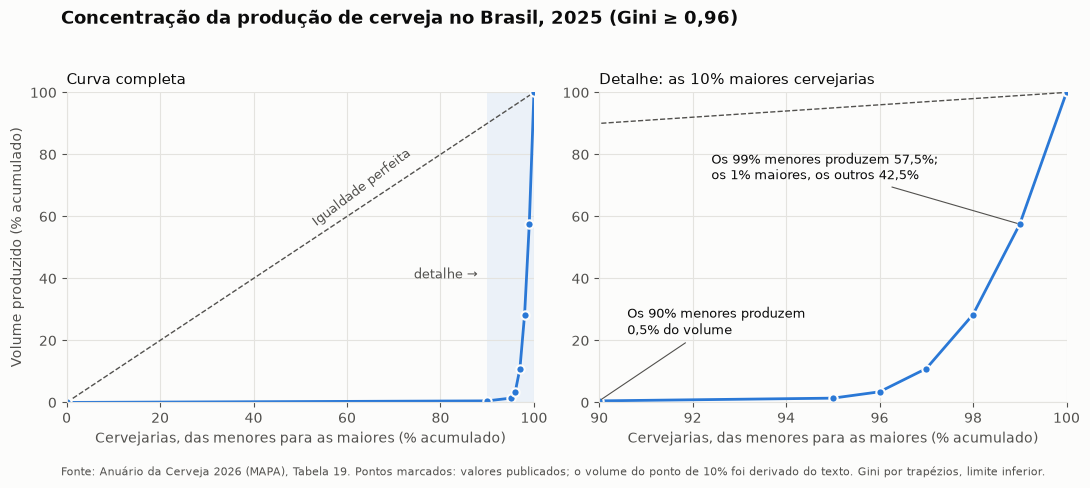

In [4]:
fig, (ax_geral, ax_zoom) = plt.subplots(1, 2, figsize=(11, 4.8))

for ax in (ax_geral, ax_zoom):
    ax.plot([0, 100], [0, 100], color=COR_TEXTO_2, linewidth=1, linestyle="--")
    ax.plot(
        lorenz_2025["pop_acumulada"] * 100,
        lorenz_2025["volume_acumulado"] * 100,
        color=COR_SERIE, linewidth=2, marker="o", markersize=6,
        markeredgecolor=COR_FUNDO, markeredgewidth=1.5,
    )
    ax.set_xlabel("Cervejarias, das menores para as maiores (% acumulado)")

ax_geral.set_xlim(0, 100)
ax_geral.set_ylim(0, 100)
ax_geral.set_ylabel("Volume produzido (% acumulado)")
ax_geral.set_title("Curva completa", loc="left", color=COR_TEXTO, fontsize=11)
ax_geral.text(52, 57, "Igualdade perfeita", color=COR_TEXTO_2, rotation=37, fontsize=9)
ax_geral.axvspan(90, 100, color=COR_SERIE, alpha=0.08, linewidth=0)
ax_geral.text(88, 40, "detalhe →", color=COR_TEXTO_2, fontsize=9, ha="right")

ax_zoom.set_xlim(90, 100)
ax_zoom.set_ylim(0, 100)
ax_zoom.set_title("Detalhe: as 10% maiores cervejarias", loc="left", color=COR_TEXTO, fontsize=11)
ax_zoom.annotate(
    "Os 99% menores produzem 57,5%;\nos 1% maiores, os outros 42,5%",
    xy=(99, 57.51), xytext=(92.4, 72),
    color=COR_TEXTO, fontsize=9,
    arrowprops=dict(arrowstyle="-", color=COR_TEXTO_2, linewidth=0.8),
)
ax_zoom.annotate(
    "Os 90% menores produzem\n0,5% do volume",
    xy=(90, 0.5), xytext=(90.6, 22),
    color=COR_TEXTO, fontsize=9,
    arrowprops=dict(arrowstyle="-", color=COR_TEXTO_2, linewidth=0.8),
)

titulo = f"Concentração da produção de cerveja no Brasil, 2025 (Gini ≥ {gini_2025:.2f})"
fig.suptitle(titulo.replace(".", ","), x=0.06, ha="left", fontsize=13, color=COR_TEXTO, fontweight="bold")
fig.text(
    0.06, 0.01,
    "Fonte: Anuário da Cerveja 2026 (MAPA), Tabela 19. Pontos marcados: valores publicados; "
    "o volume do ponto de 10% foi derivado do texto. Gini por trapézios, limite inferior.",
    fontsize=8, color=COR_TEXTO_2,
)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
fig.savefig(PASTA_FIGURAS / "lorenz_2025.png", dpi=150)
plt.show()

**Resposta:** a produção de cerveja no Brasil é extremamente concentrada. **O índice de Gini é de pelo menos 0,96** (em uma escala de 0 a 1). Os 1% maiores produtores respondem por 42,5% do volume, e os 90% menores, juntos, por apenas 0,5%.

## 2. A concentração mudou de 2024 para 2025?

Dois cuidados nesta comparação:

1. **Mesmos pontos nos dois anos.** O Anuário 2025 não traz o ponto de 10%, então o Gini dos dois anos é calculado só com os pontos de 1% a 5%.
2. **A retificação de 2024.** As fatias de 2024 foram calculadas sobre o total original (15,34 bi L). O Anuário 2026 acrescentou 1,87 bi L a esse ano sem dizer a quem. Para cada fatia, calculamos a faixa de valores possíveis de 2024: do cenário em que nenhum litro retificado é dessas cervejarias ao cenário em que todos são.

In [5]:
TOTAL_2024_ORIGINAL = 15_344_065_267.36
TOTAL_2024_RETIFICADO = 17_210_754_610.75
RETIFICACAO = TOTAL_2024_RETIFICADO - TOTAL_2024_ORIGINAL

conc_2024 = pd.read_csv(PASTA_SAIDA / "concentracao_2024.csv")
conc_2025_comparavel = conc_2025[conc_2025["pct_cervejarias"] <= 5]

lorenz_2024 = pontos_lorenz(conc_2024["pct_cervejarias"], conc_2024["pct_volume"])
lorenz_2025_comparavel = pontos_lorenz(conc_2025_comparavel["pct_cervejarias"], conc_2025_comparavel["pct_volume"])

gini_2024 = gini_trapezios(lorenz_2024["pop_acumulada"], lorenz_2024["volume_acumulado"])
gini_2025_comparavel = gini_trapezios(lorenz_2025_comparavel["pop_acumulada"], lorenz_2025_comparavel["volume_acumulado"])

print(f"Gini 2024 (pontos de 1% a 5%): {gini_2024:.4f}")
print(f"Gini 2025 (pontos de 1% a 5%): {gini_2025_comparavel:.4f}")

Gini 2024 (pontos de 1% a 5%): 0.9623
Gini 2025 (pontos de 1% a 5%): 0.9567


In [6]:
comparacao = conc_2024[["pct_cervejarias", "volume_litros", "pct_volume"]].merge(
    conc_2025_comparavel[["pct_cervejarias", "pct_volume"]],
    on="pct_cervejarias",
    suffixes=("_2024", "_2025"),
)
comparacao["dif_pontos"] = comparacao["pct_volume_2025"] - comparacao["pct_volume_2024"]

comparacao["min_2024_retificado"] = comparacao["volume_litros"] / TOTAL_2024_RETIFICADO * 100
comparacao["max_2024_retificado"] = (
    (comparacao["volume_litros"] + RETIFICACAO) / TOTAL_2024_RETIFICADO * 100
).clip(upper=100)

comparacao["conclusao"] = "indeterminada"
comparacao.loc[comparacao["pct_volume_2025"] < comparacao["min_2024_retificado"], "conclusao"] = "caiu"
comparacao.loc[comparacao["pct_volume_2025"] > comparacao["max_2024_retificado"], "conclusao"] = "subiu"

comparacao.drop(columns="volume_litros")

,pct_cervejarias,pct_volume_2024,pct_volume_2025,dif_pontos,min_2024_retificado,max_2024_retificado,conclusao
0,1.0000,47.7300,42.4900,-5.2400,42.5534,53.3994,caiu
1,2.0000,76.8700,71.6400,-5.2300,68.5346,79.3807,indeterminada
2,3.0000,92.9400,89.0700,-3.8700,82.8620,93.7080,indeterminada
3,4.0000,98.1100,96.5700,-1.5400,87.4652,98.3112,indeterminada
4,5.0000,98.8700,98.6200,-0.2500,88.1432,98.9892,indeterminada


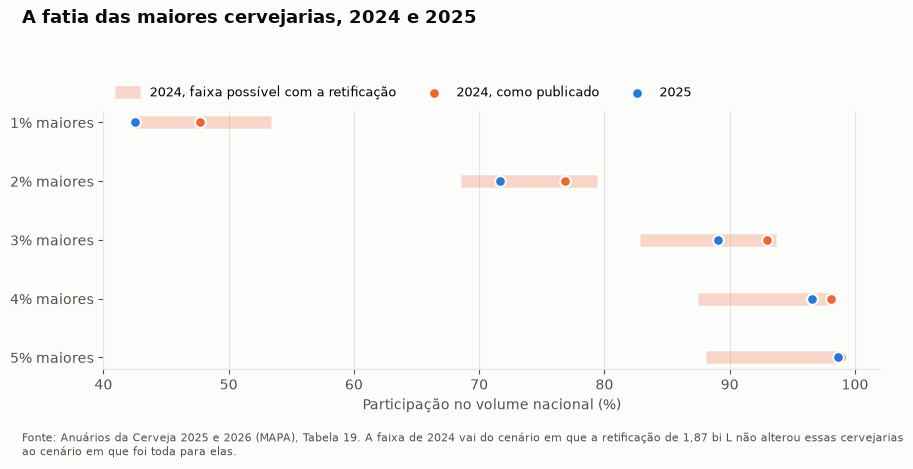

In [7]:
COR_2024 = "#eb6834"

fig, ax = plt.subplots(figsize=(9, 4.6))
posicoes = range(len(comparacao))
rotulos = [f"{p:.0f}% maiores" for p in comparacao["pct_cervejarias"]]

ax.hlines(
    posicoes, comparacao["min_2024_retificado"], comparacao["max_2024_retificado"],
    color=COR_2024, alpha=0.25, linewidth=9, label="2024, faixa possível com a retificação",
)
ax.scatter(
    comparacao["pct_volume_2024"], posicoes, color=COR_2024, s=60,
    edgecolor=COR_FUNDO, linewidth=1.5, zorder=3, label="2024, como publicado",
)
ax.scatter(
    comparacao["pct_volume_2025"], posicoes, color=COR_SERIE, s=60,
    edgecolor=COR_FUNDO, linewidth=1.5, zorder=4, label="2025",
)

ax.set_yticks(list(posicoes), rotulos)
ax.invert_yaxis()
ax.set_xlim(40, 102)
ax.set_xlabel("Participação no volume nacional (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9)

fig.suptitle(
    "A fatia das maiores cervejarias, 2024 e 2025",
    x=0.03, ha="left", fontsize=13, color=COR_TEXTO, fontweight="bold",
)
fig.text(
    0.03, 0.01,
    "Fonte: Anuários da Cerveja 2025 e 2026 (MAPA), Tabela 19. A faixa de 2024 vai do cenário em que a retificação "
    "de 1,87 bi L não alterou essas cervejarias\nao cenário em que foi toda para elas.",
    fontsize=8, color=COR_TEXTO_2,
)
fig.tight_layout(rect=(0, 0.07, 1, 0.93))
fig.savefig(PASTA_FIGURAS / "concentracao_2024_2025.png", dpi=150)
plt.show()

**Resposta:** pelos dados publicados, a concentração caiu levemente: o Gini (pontos de 1% a 5%) passou de 0,962 para 0,957, e a fatia do 1% maior, de 47,7% para 42,5% do volume.

Mas a retificação de 2024 limita o que dá para afirmar:

- **O 1% maior perdeu participação em qualquer cenário.** Mesmo que nenhum litro retificado fosse dessas cervejarias, a fatia delas em 2024 seria de 42,6%, ainda acima dos 42,5% de 2025. A queda vai de praticamente zero a 10,9 pontos percentuais, e o cenário de queda quase nula é improvável: 1,87 bilhão de litros em cervejarias menores as transformaria em grandes.
- **Para as fatias de 2% a 5%, a direção é indeterminada.** Os valores de 2025 ficam dentro da faixa possível de 2024.

Conclusão: **a concentração não aumentou**, e o grupo das maiores cervejarias perdeu espaço. A "leve desconcentração" que o Anuário descreve é compatível com os dados, mas o tamanho dela não pode ser medido com precisão.

## 3. Como a estrutura do setor varia entre regiões?

O Anuário não traz dados por cervejaria dentro de cada região, então não é possível calcular um índice de Gini regional. Comparamos o **porte típico** das cervejarias de cada região com três indicadores:

- **Produção média por cervejaria** (Tabela 18);
- **Empregos por cervejaria** (Tabela 16 agregada por região);
- **Litros produzidos por emprego**, uma medida aproximada de escala industrial.

In [8]:
t18 = pd.read_csv(PASTA_SAIDA / "tabela_18_producao_media_regiao_2025.csv")
t16 = pd.read_csv(PASTA_SAIDA / "tabela_16_empregos_uf_2025.csv")
uf_regiao = pd.read_csv(PASTA_SAIDA / "grafico_02_cervejarias_uf_2025.csv")[["uf", "regiao"]]

empregos_uf = t16.merge(uf_regiao, on="uf", how="left")
print("UFs sem região:", empregos_uf["regiao"].isna().sum())
empregos_regiao = empregos_uf.groupby("regiao")["estoque_empregos"].sum()

regioes = (
    t18.set_index("regiao")[["volume_litros", "n_cervejarias", "producao_media_litros"]]
    .join(empregos_regiao)
)
regioes["pct_volume"] = regioes["volume_litros"] / regioes["volume_litros"].sum() * 100
regioes["pct_cervejarias"] = regioes["n_cervejarias"] / regioes["n_cervejarias"].sum() * 100
regioes["empregos_por_cervejaria"] = regioes["estoque_empregos"] / regioes["n_cervejarias"]
regioes["litros_por_emprego"] = regioes["volume_litros"] / regioes["estoque_empregos"]
regioes = regioes.sort_values("producao_media_litros", ascending=False)

regioes.round(1)

UFs sem região: 0


,volume_litros,n_cervejarias,producao_media_litros,estoque_empregos,pct_volume,pct_cervejarias,empregos_por_cervejaria,litros_por_emprego
regiao,,,,,,,,
Nordeste,"3,802,222,465.1000",130,"29,247,865.1000",6873,24.2000,6.7000,52.9000,"553,211.5000"
Centro-Oeste,"1,054,248,799.2000",98,"10,757,640.8000",2532,6.7000,5.0000,25.8000,"416,370.0000"
Sudeste,"8,168,433,821.1000",923,"8,849,874.1000",24358,52.1000,47.2000,26.4000,"335,349.1000"
Norte,"215,667,722.0000",44,"4,901,539.1000",1502,1.4000,2.3000,34.1000,"143,587.0000"
Sul,"2,447,510,384.2000",759,"3,224,651.4000",6711,15.6000,38.8000,8.8000,"364,701.3000"


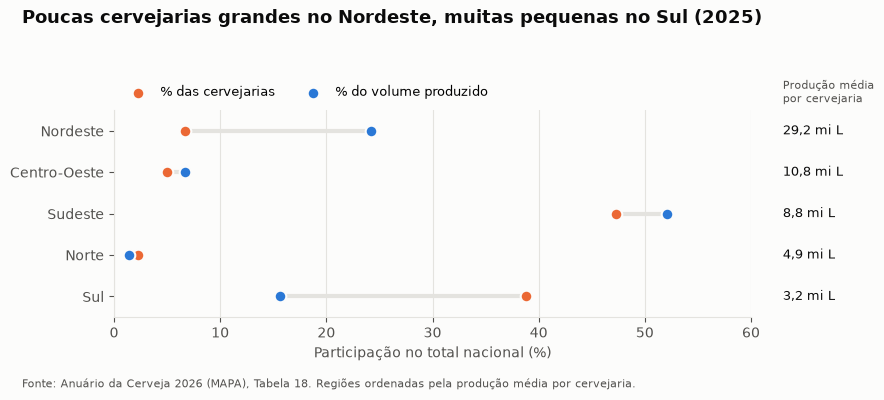

In [9]:
COR_CERVEJARIAS = "#eb6834"

fig, ax = plt.subplots(figsize=(9, 3.9))
posicoes = range(len(regioes))

ax.hlines(posicoes, regioes["pct_cervejarias"], regioes["pct_volume"], color=COR_GRADE, linewidth=3, zorder=1)
ax.scatter(
    regioes["pct_cervejarias"], posicoes, color=COR_CERVEJARIAS, s=70,
    edgecolor=COR_FUNDO, linewidth=1.5, zorder=3, label="% das cervejarias",
)
ax.scatter(
    regioes["pct_volume"], posicoes, color=COR_SERIE, s=70,
    edgecolor=COR_FUNDO, linewidth=1.5, zorder=3, label="% do volume produzido",
)

for posicao, (regiao, linha) in zip(posicoes, regioes.iterrows()):
    media_mi = linha["producao_media_litros"] / 1_000_000
    ax.text(63, posicao, f"{media_mi:.1f} mi L".replace(".", ","), va="center", fontsize=9, color=COR_TEXTO)

ax.text(63, -0.6, "Produção média\npor cervejaria", fontsize=8, color=COR_TEXTO_2, va="bottom")
ax.set_yticks(list(posicoes), regioes.index)
ax.set_ylim(len(regioes) - 0.5, -0.5)
ax.set_xlim(0, 60)
ax.set_xlabel("Participação no total nacional (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9)

fig.suptitle(
    "Poucas cervejarias grandes no Nordeste, muitas pequenas no Sul (2025)",
    x=0.03, ha="left", fontsize=13, color=COR_TEXTO, fontweight="bold",
)
fig.text(
    0.03, 0.01,
    "Fonte: Anuário da Cerveja 2026 (MAPA), Tabela 18. Regiões ordenadas pela produção média por cervejaria.",
    fontsize=8, color=COR_TEXTO_2,
)
fig.tight_layout(rect=(0, 0.04, 1, 0.93))
fig.subplots_adjust(right=0.84)
fig.savefig(PASTA_FIGURAS / "regioes_2025.png", dpi=150)
plt.show()

In [10]:
TOTAL_2025 = 15_688_083_191.69
N_CERVEJARIAS = 1_954

volume_1pct_maiores = conc_2025.loc[conc_2025["pct_cervejarias"] == 1, "volume_litros"].iloc[0]
volume_90pct_menores = TOTAL_2025 * 0.005

media_1pct_maiores = volume_1pct_maiores / (0.01 * N_CERVEJARIAS)
media_90pct_menores = volume_90pct_menores / (0.90 * N_CERVEJARIAS)

print(f"1% maiores:  cerca de {0.01 * N_CERVEJARIAS:.0f} cervejarias, média de {media_1pct_maiores / 1e6:,.0f} milhões de L por ano")
print(f"90% menores: cerca de {0.90 * N_CERVEJARIAS:,.0f} cervejarias, média de {media_90pct_menores / 1e3:,.0f} mil L por ano")
print(f"Uma grande produz, em média, {media_1pct_maiores / media_90pct_menores:,.0f} vezes mais que uma pequena")

1% maiores:  cerca de 20 cervejarias, média de 341 milhões de L por ano
90% menores: cerca de 1,759 cervejarias, média de 45 mil L por ano
Uma grande produz, em média, 7,649 vezes mais que uma pequena


**Resposta:** a estrutura do setor é muito diferente entre as regiões.

- **Nordeste:** 6,7% das cervejarias e 24,2% do volume. É a maior produção média (29,2 milhões de L por cervejaria) e a maior produção por emprego (553 mil L), sinal de grandes plantas industriais.
- **Sul:** o extremo oposto. Tem 38,8% das cervejarias e 15,6% do volume, com produção média de 3,2 milhões de L e apenas 8,8 empregos por cervejaria: muitas cervejarias pequenas.
- **Sudeste:** concentra mais da metade do volume (52,1%) e quase metade das cervejarias, com porte intermediário.

No país como um todo, estimamos que cerca de 20 cervejarias produzem em média 341 milhões de L por ano, enquanto as cerca de 1.759 menores produzem em média 45 mil L, uma diferença de aproximadamente 7.600 vezes. A estimativa usa as 1.954 cervejarias registradas como aproximação do número de declarantes.

## Conclusão 

1. **A produção é extremamente concentrada.** O índice de Gini é de pelo menos 0,96, e os 1% maiores produtores respondem por 42,5% do volume.
2. **A concentração não aumentou de 2024 para 2025.** A fatia do 1% maior caiu em qualquer cenário da retificação de 2024; o tamanho da queda não pode ser medido com precisão.
3. **O porte das cervejarias varia muito por região.** O Nordeste tem poucas plantas grandes (29,2 milhões de L por cervejaria); o Sul, muitas pequenas (3,2 milhões de L).